In [ ]:
import kagglehub
path = kagglehub.dataset_download("maneesh99/signs-detection-dataset")
print(path)

100%|██████████| 8.88M/8.88M [00:00<00:00, 11.2MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/maneesh99/signs-detection-dataset/versions/2


In [ ]:
import os

for file in os.listdir(path):
    print(file)

Signs_Data_Testing.h5
Signs_Data_Training.h5


In [ ]:
import h5py
import numpy as np

with h5py.File(os.path.join(path, "Signs_Data_Training.h5"), "r") as file:
    print(list(file.keys()))


['list_classes', 'train_set_x', 'train_set_y']


In [ ]:
# Load the training data
with h5py.File(os.path.join(path, "Signs_Data_Training.h5"), "r") as file:
    X_train = np.array(file["train_set_x"])
    Y_train = np.array(file["train_set_y"])
    classes = np.array(file["list_classes"])

# Load the testing data
with h5py.File(os.path.join(path, "Signs_Data_Testing.h5"), "r") as file:
    X_test = np.array(file["test_set_x"])
    Y_test = np.array(file["test_set_y"])

print("Training images:", X_train.shape)
print("Training labels:", Y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", Y_test.shape)

Training images: (1080, 64, 64, 3)
Training labels: (1080,)
Testing images: (120, 64, 64, 3)
Testing labels: (120,)


Classes: [0 1 2 3 4 5]
Labels: [0 1 2 3 4 5]


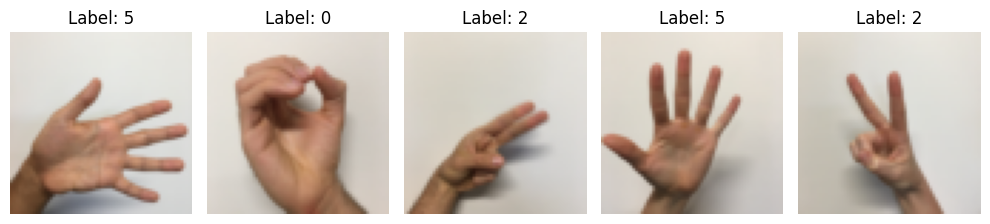

In [ ]:
import matplotlib.pyplot as plt
# Check the available classes and label values
print("Classes:", classes)
print("Labels:", np.unique(Y_train))

# Display a few training images
plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Label: {Y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Convert pixel values from 0–255 to 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.2,
    random_state=42,
    stratify=Y_train
)

In [ ]:
print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)

Training: (864, 64, 64, 3) (864,)
Validation: (216, 64, 64, 3) (216,)
Testing: (120, 64, 64, 3) (120,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(64, 64, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(6, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,926 (6.20 MB)

 Trainable params: 1,625,926 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 163ms/step - accuracy: 0.1898 - loss: 1.8753 - val_accuracy: 0.3889 - val_loss: 1.7439
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 202ms/step - accuracy: 0.4525 - loss: 1.5758 - val_accuracy: 0.6111 - val_loss: 1.2703
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 154ms/step - accuracy: 0.6285 - loss: 1.0826 - val_accuracy: 0.6759 - val_loss: 0.8999
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.7581 - loss: 0.7304 - val_accuracy: 0.7685 - val_loss: 0.6759
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - accuracy: 0.8588 - loss: 0.4987 - val_accuracy: 0.7824 - val_loss: 0.6073
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 166ms/step - accuracy: 0.8576 - loss: 0.4233 - val_accuracy: 0.7639 - val_loss: 0.6162
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 168ms/step - accuracy: 0.8900 - loss: 0.3564 - val_accuracy: 0.8102 - val_loss: 0.5386
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.9456 - loss: 0.1999 - val_accuracy: 0.

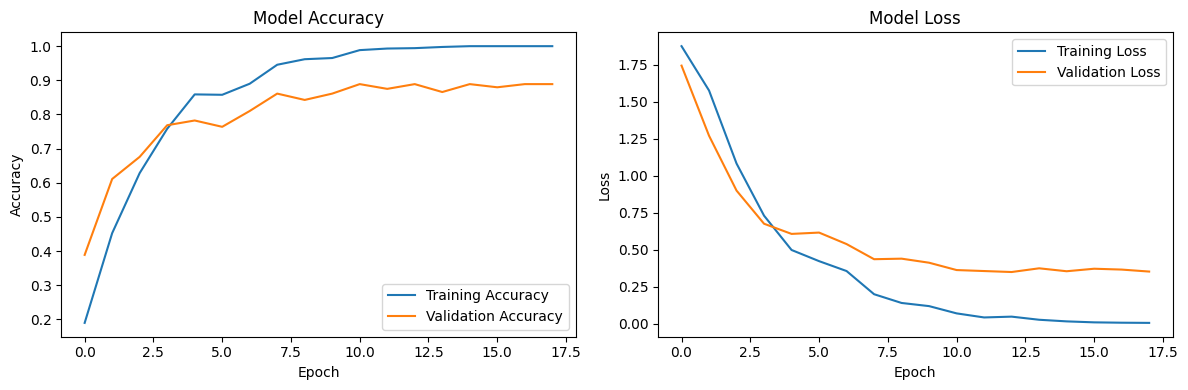

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")


Test accuracy: 89.17%
Test loss: 0.2925


              precision    recall  f1-score   support

           0       1.00      0.95      0.97        20
           1       1.00      0.90      0.95        20
           2       0.83      0.95      0.88        20
           3       0.90      0.95      0.93        20
           4       0.93      0.65      0.76        20
           5       0.76      0.95      0.84        20

    accuracy                           0.89       120
   macro avg       0.90      0.89      0.89       120
weighted avg       0.90      0.89      0.89       120



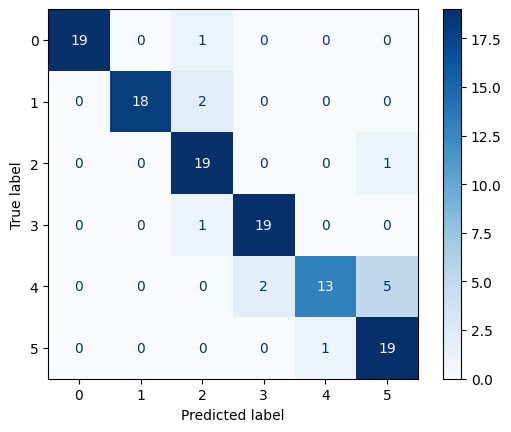

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

Y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(Y_test, Y_pred, labels=[0, 1, 2, 3, 4, 5], zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix(Y_test, Y_pred, labels=[0, 1, 2, 3, 4, 5]),
    display_labels=[0, 1, 2, 3, 4, 5]
).plot(cmap="Blues")

plt.show()

In [ ]:

from tensorflow.keras.applications.resnet50 import preprocess_input

X_train_resnet = preprocess_input(X_train * 255.0)
X_val_resnet = preprocess_input(X_val * 255.0)
X_test_resnet = preprocess_input(X_test * 255.0)


In [ ]:

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dropout, Dense

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

inputs = Input(shape=(64, 64, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(6, activation="softmax")(x)

resnet_model = Model(inputs, outputs)

resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2, 2, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,600,006 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

resnet_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

resnet_history = resnet_model.fit(
    X_train_resnet, Y_train,
    validation_data=(X_val_resnet, Y_val),
    epochs=20,
    batch_size=16,
    callbacks=[resnet_early_stopping]
)

Epoch 1/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 319ms/step - accuracy: 0.5208 - loss: 1.8606 - val_accuracy: 0.7315 - val_loss: 0.8101
Epoch 2/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 19s 282ms/step - accuracy: 0.7512 - loss: 0.8304 - val_accuracy: 0.8241 - val_loss: 0.4670
Epoch 3/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 20s 272ms/step - accuracy: 0.8391 - loss: 0.4833 - val_accuracy: 0.8194 - val_loss: 0.4459
Epoch 4/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 23s 316ms/step - accuracy: 0.8495 - loss: 0.4160 - val_accuracy: 0.8519 - val_loss: 0.4385
Epoch 5/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 20s 317ms/step - accuracy: 0.8900 - loss: 0.2843 - val_accuracy: 0.8796 - val_loss: 0.3071
Epoch 6/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 14s 269ms/step - accuracy: 0.8935 - loss: 0.2537 - val_accuracy: 0.8565 - val_loss: 0.3552
Epoch 7/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 318ms/step - accuracy: 0.9317 - loss: 0.1915 - val_accuracy: 0.9167 - val_loss: 0.2878
Epoch 8/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 15s 271ms/step - accuracy: 0.9421 - loss: 0.1507 - val_accu

In [ ]:
resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    X_test_resnet, Y_test, verbose=0
)

print(f"ResNet50 test accuracy: {resnet_test_accuracy:.2%}")
print(f"ResNet50 test loss: {resnet_test_loss:.4f}")

ResNet50 test accuracy: 95.83%
ResNet50 test loss: 0.1531


In [ ]:
print(f"Baseline CNN: {test_accuracy:.2%}")
print(f"ResNet50:     {resnet_test_accuracy:.2%}")

Baseline CNN: 89.17%
ResNet50:     95.83%
